# PricePulse
### Sri Lankan Retail Price Forecasting Using Ensemble Learning

## 1. Project Introduction

Forecast the **next reported Colombo retail price** in Sri Lankan rupees (LKR).
Compare bagging, boosting and stacking against a forecast that carries the latest price forward.

## 2. Dataset Information

- **Publisher** · Sri Lanka Department of Census and Statistics (DCS), Colombo District open-market weekly average retail prices.
- **Snapshot** · Macro Lab requires an account for full-history downloads. The included CSV is a wide-format export of the public DCS dashboard data.
- **Time axis** · DCS labels weeks within each month. Days 7, 14, 21 and 28 mark those periods.

[DCS retail-price dashboard](https://www.statistics.gov.lk/DashBoard/Prices/) · [Macro Lab catalogue](https://macrolab.lk/data/prices-and-inflation/retail-weekly/)

## 3. Data Loading

In [27]:
from pathlib import Path
import sys

root = next(
    folder for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "data" / "retail-weekly-w.csv").is_file()
)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src.evaluation import NAIVE, PREDICTIONS, save_results, score_partition, select_ensemble
from src.features import FEATURES, TARGET, build_features, chronological_partitions, partition_summary
from src.preprocessing import choose_products, observed_prices, read_retail_csv, split_dates
from src.training import BOOSTING, FOREST, STACKING, ChronologicalStackingRegressor, fit_base_model, save_models

wide = read_retail_csv(root / "data" / "retail-weekly-w.csv")
print(f"{len(wide):,} reporting periods · {len(wide.columns) - 1} product columns")
print(f"{wide.period.min():%d %b %Y} to {wide.period.max():%d %b %Y}")
display(wide.iloc[:3, :5].set_index("period"))

324 reporting periods · 128 product columns
28 Dec 2019 to 07 Nov 2026


,Anamalu (1 kg) (Rs),Anchor (400g) (Rs),Arecanuts average 100 nuts (Rs),Arecanuts medium 100 nuts (Rs)
period,,,,
2019-12-28,191.43,380.0,570.14,677.78
2020-01-07,188.42,380.0,547.78,655.56
2020-01-14,184.62,380.0,562.86,690.00


## 4. Data Cleaning and Preparation

Reshape the source to `date | product | price_lkr` and keep positive, finite reported prices.
Select 24 products by observation coverage within the training dates, with a minimum of 80% and alphabetical tie-breaking.
The CSV headings retain the DCS names and units.

In [28]:
all_observed = observed_prices(wide)
validation_start, test_start = split_dates(wide)
coverage = choose_products(all_observed, wide, validation_start)
observed = all_observed[all_observed["product"].isin(coverage.index)]

price_cells = len(wide) * (wide.shape[1] - 1)
print(f"{price_cells:,} source price cells − {price_cells - len(all_observed):,} "
      f"missing or nonpositive entries = {len(all_observed):,} observed prices")
print(f"{len(observed):,} observed prices across {len(coverage)} selected products")
print(f"Training-period coverage: {coverage.min():.1%}–{coverage.max():.1%}")
display(observed.head(3).set_index("date"))

41,472 source price cells − 4,842 missing or nonpositive entries = 36,630 observed prices
7,776 observed prices across 24 selected products
Training-period coverage: 100.0%–100.0%


,product,price_lkr
date,,
2019-12-28,Anamalu (1 kg) (Rs),191.43
2020-01-07,Anamalu (1 kg) (Rs),188.42
2020-01-14,Anamalu (1 kg) (Rs),184.62


## 5. Exploratory Data Analysis

Three common products illustrate different price levels and patterns over time.

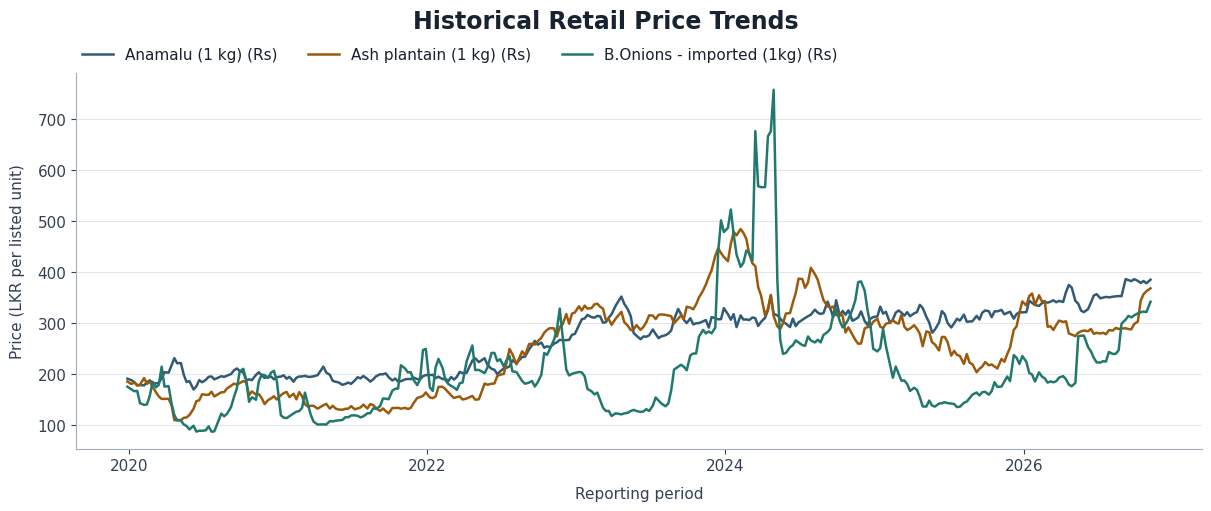

In [29]:
palette = {
    FOREST: "#315b74",
    BOOSTING: "#9b590a",
    STACKING: "#21786c",
    NAIVE: "#626a78",
}
plt.rcParams.update({
    "figure.dpi": 100, "font.size": 11, "axes.titlesize": 17,
    "axes.titleweight": "bold", "axes.titlepad": 16, "axes.labelpad": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#a2adba", "axes.labelcolor": "#344054",
    "text.color": "#182230", "xtick.color": "#344054", "ytick.color": "#344054",
    "grid.color": "#dadee5", "legend.frameon": False,
})


def date_axis(ax):
    locator = mdates.AutoDateLocator(minticks=4, maxticks=7)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))


def top_legend(ax, columns):
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01, 1, 0.12),
              ncol=columns, borderaxespad=0)


examples = [p for p in ("Anamalu 1Kg", "Bread 450g", "Carrot 1kg") if p in coverage.index]
if len(examples) < 3:
    examples.extend(p for p in coverage.index if p not in examples)
examples = examples[:3]

fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
for product, color in zip(examples, ("#315b74", "#9b590a", "#21786c")):
    history = observed[observed["product"].eq(product)]
    ax.plot(history["date"], history["price_lkr"], color=color, label=product, linewidth=1.8)
fig.suptitle("Historical Retail Price Trends", fontsize=17, fontweight="bold")
ax.set(xlabel="Reporting period", ylabel="Price (LKR per listed unit)")
ax.grid(axis="y", alpha=0.75)
date_axis(ax)
top_legend(ax, 3)
plt.show()
plt.close(fig)

## 6. Feature Engineering

- **Inputs** · Product, current price, three observed lags, two price changes, four-observation rolling mean and standard deviation, days since the prior reading, month and ISO week.
- **Target** · The next observed price and its reporting period for the same product. The regressors learn its change from the current price, which is added back before evaluation.
- The first three readings per product establish history. The latest unlabeled reading supports dashboard forecasting.

In [30]:
features = build_features(observed)
labeled = features.dropna(subset=[TARGET])
assert labeled["target_date"].gt(labeled["date"]).all()
print(f"{len(labeled):,} rows with features and a next reported price")
display(labeled[["date", "product", "price_lkr", "lag_1", "target_date", TARGET]]
        .head(3).set_index("date"))

7,680 rows with features and a next reported price


,product,price_lkr,lag_1,target_date,target_price_lkr
date,,,,,
2020-01-21,Anamalu (1 kg) (Rs),178.89,184.62,2020-01-28,178.83
2020-01-21,Ash plantain (1 kg) (Rs),177.57,184.38,2020-01-28,179.74
2020-01-21,B.Onions - imported (1kg) (Rs),167.57,166.71,2020-01-28,143.28


## 7. Chronological Data Splitting

Use approximately **70% train / 15% validation / 15% test** by distinct source periods.
Drop rows whose target crosses the next split boundary.
Historical observations through each origin remain available for rolling one-report-ahead evaluation.

In [31]:
partitions = chronological_partitions(features, validation_start, test_start)
train, validation, test = (partitions[name] for name in ("Train", "Validation", "Test"))
assert train["target_date"].max() < validation["date"].min()
assert validation["target_date"].max() < test["date"].min()
print(f"{len(labeled) - sum(map(len, partitions.values())):,} labeled rows removed at split boundaries")
display(partition_summary(partitions))

48 labeled rows removed at split boundaries


,Rows,First origin,Last origin,Last target
Train,5328,2020-01-21,2024-10-14,2024-10-21
Validation,1152,2024-10-28,2025-10-21,2025-10-28
Test,1152,2025-11-07,2026-10-28,2026-11-07


## 8. Bagging — Random Forest

Average 96 bootstrapped trees. Limit depth and minimum leaf size to control variance.
Fit the product one-hot encoder within the training pipeline.

In [32]:
models = {FOREST: fit_base_model(FOREST, train)}
print(f"Fitted {FOREST} on {len(train):,} training rows")

Fitted Random Forest on 5,328 training rows


## 9. Boosting — Gradient Boosting

Fit 120 shallow trees in sequence. Huber loss reduces sensitivity to abrupt price changes.
Use a separately fitted training pipeline with the same inputs.

In [33]:
models[BOOSTING] = fit_base_model(BOOSTING, train)
print(f"Fitted {BOOSTING} on {len(train):,} training rows")

Fitted Gradient Boosting on 5,328 training rows


## 10. Stacking — Stacking Regressor

A custom chronological stacking regressor uses **five expanding-window folds**.
In each fold, fit fresh encoders and base regressors on earlier dates whose targets are already known.
Fit a Ridge meta-regressor on the resulting out-of-fold predictions. At inference it combines the two full-training base models.

In [34]:
models[STACKING] = ChronologicalStackingRegressor().fit(train, models)
folds = models[STACKING].fold_summary_
assert folds["Last fit target"].lt(folds["First fold origin"]).all()
display(folds)

,Last fit target,First fold origin,Last fold origin,Fit rows,Out-of-fold rows
Fold,,,,,
1,2020-10-28,2020-11-07,2021-08-14,864,888
2,2021-08-14,2021-08-21,2022-06-07,1752,888
3,2022-06-07,2022-06-14,2023-03-21,2640,888
4,2023-03-21,2023-03-28,2024-01-07,3528,888
5,2024-01-07,2024-01-14,2024-10-14,4416,888


## 11. Model Evaluation

The **naive baseline** carries forward the latest observed price. Choose the ensemble with the lowest validation MAE, then measure it and the other approaches on the held-out test set.
MAE and RMSE are in LKR. R² is unitless.

In [35]:
validation_metrics, _ = score_partition(validation, models, "Validation")
best_model = select_ensemble(validation_metrics)
test_metrics, test_predictions = score_partition(test, models, "Test")
metrics = pd.concat([validation_metrics, test_metrics], ignore_index=True)

report = metrics.rename(columns={"mae_lkr": "MAE", "rmse_lkr": "RMSE", "r2": "R²"})
display(report.set_index(["split", "model"])[["MAE", "RMSE", "R²"]].round(3))
print(f"Selected by validation MAE: {best_model}")

save_results(root / "results", metrics, test_predictions)
save_models(root / "models" / "ensemble_models.joblib", models, best_model, coverage.index, train)

MAE    RMSE     R²
split      model                                   
Validation Random Forest      35.169  78.180  0.996
           Gradient Boosting  34.830  77.357  0.996
           Stacking           34.189  73.773  0.997
           Naive Baseline     34.362  73.734  0.997
Test       Random Forest      29.476  78.165  0.997
           Gradient Boosting  29.230  78.012  0.997
           Stacking           26.557  66.463  0.998
           Naive Baseline     24.649  60.200  0.998

Selected by validation MAE: Stacking


## 12. Visual Comparison

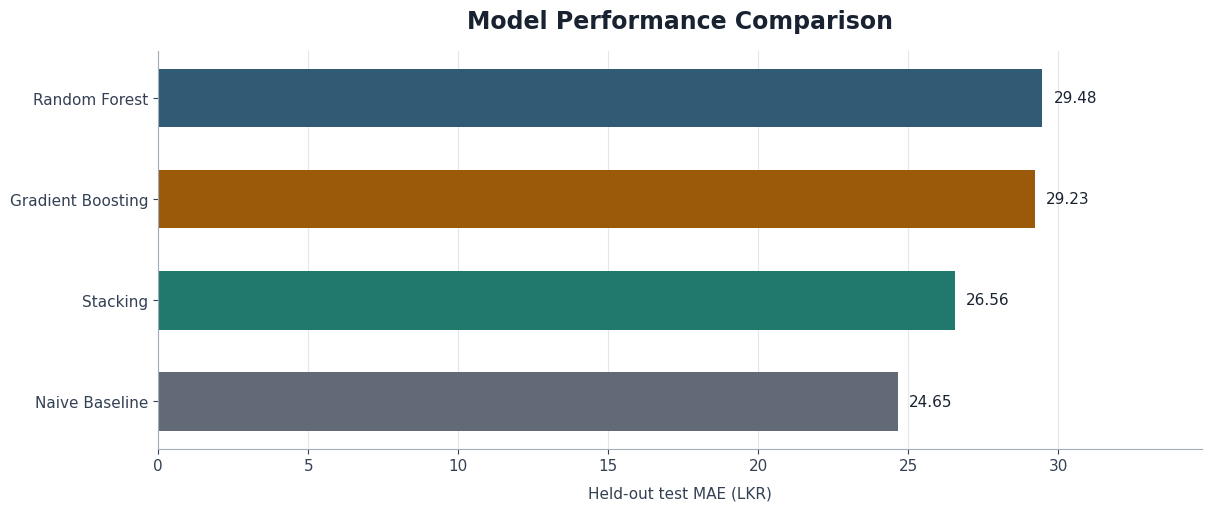

In [36]:
fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
mae = test_metrics.set_index("model")["mae_lkr"]
bars = ax.barh(mae.index, mae, color=[palette[name] for name in mae.index], height=0.58)
ax.bar_label(bars, labels=[f"{value:.2f}" for value in mae], padding=8, fontsize=11)
ax.set_xlim(0, mae.max() * 1.18)
ax.invert_yaxis()
ax.set(title="Model Performance Comparison", xlabel="Held-out test MAE (LKR)")
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.75)
plt.show()
plt.close(fig)

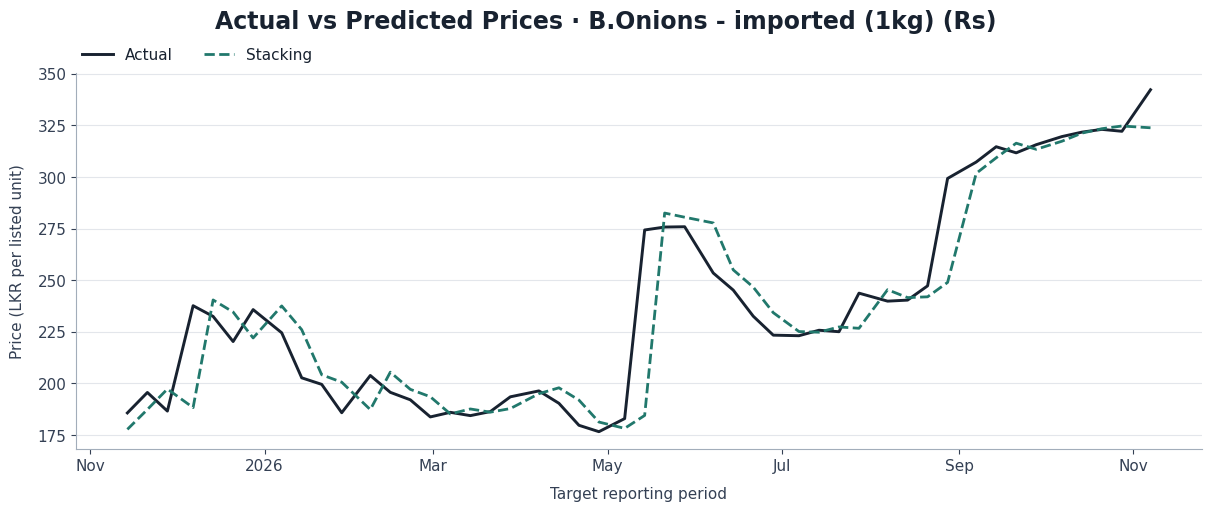

In [37]:
representative = next(
    product for product in reversed(examples) if product in test_predictions["product"].values
)
held_out = test_predictions[test_predictions["product"].eq(representative)].sort_values("target_date")
fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
ax.plot(held_out["target_date"], held_out["actual_price_lkr"],
        label="Actual", color="#182230", linewidth=2.1)
ax.plot(held_out["target_date"], held_out[PREDICTIONS[best_model]],
        label=best_model, color=palette[best_model], linestyle="--", linewidth=2.0)
fig.suptitle(f"Actual vs Predicted Prices · {representative}", fontsize=17, fontweight="bold")
ax.set(xlabel="Target reporting period", ylabel="Price (LKR per listed unit)")
ax.grid(axis="y", alpha=0.75)
date_axis(ax)
top_legend(ax, 2)
plt.show()
plt.close(fig)

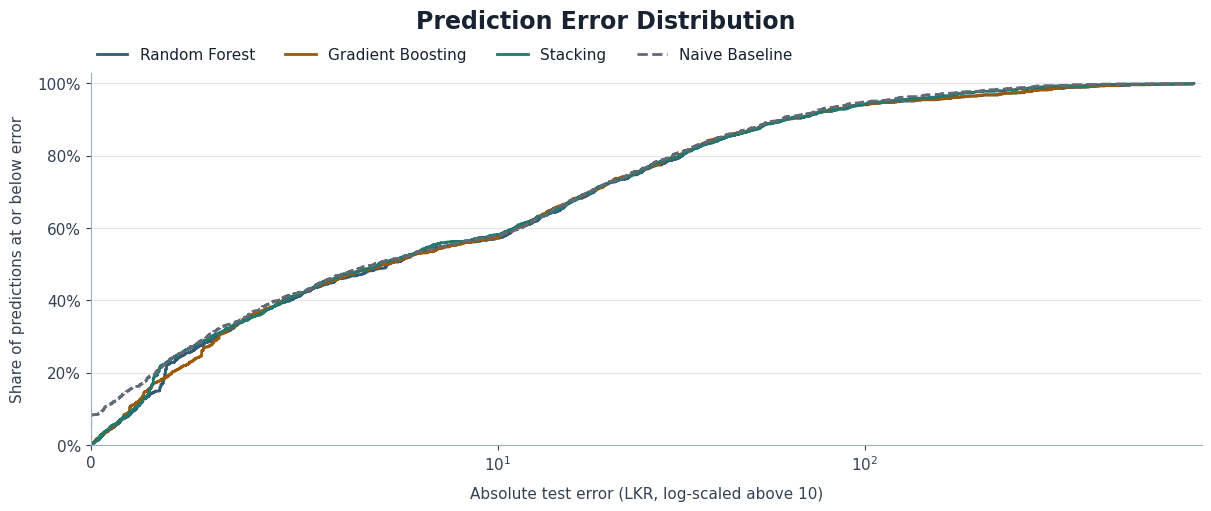

In [38]:
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
for name, column in PREDICTIONS.items():
    errors = np.sort((test_predictions["actual_price_lkr"] - test_predictions[column]).abs())
    fraction = np.arange(1, len(errors) + 1) / len(errors)
    ax.step(errors, fraction, where="post", label=name, color=palette[name],
            linewidth=2, linestyle="--" if name == NAIVE else "-")
fig.suptitle("Prediction Error Distribution", fontsize=17, fontweight="bold")
ax.set(xlabel="Absolute test error (LKR, log-scaled above 10)",
       ylabel="Share of predictions at or below error", ylim=(0, 1.03))
ax.set_xscale("symlog", linthresh=10)
ax.set_xlim(left=0)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.grid(axis="y", alpha=0.75)
top_legend(ax, 4)
plt.show()
plt.close(fig)

## 13. Conclusion and Limitations

- The forecast covers the next **observed** report for each product. Holidays and missing entries can extend the interval.
- The data cover Colombo District and use price history and calendar features. Supply shocks and policy changes can raise forecast errors.
- Pooled scores are in LKR. Price levels and typical errors differ by product and unit.

In [39]:
test_mae = test_metrics.set_index("model")["mae_lkr"]
selected_mae, naive_mae = test_mae[best_model], test_mae[NAIVE]
relative_change = (
    (test_predictions["actual_price_lkr"] - test_predictions["latest_price_lkr"]).abs()
    / test_predictions["latest_price_lkr"]
)
small_move_share = relative_change.le(0.05).mean()
comparison = (
    f"The naive baseline had lower test MAE by **{selected_mae - naive_mae:.2f} LKR**."
    if naive_mae < selected_mae else
    f"The selected ensemble reduced test MAE by **{naive_mae - selected_mae:.2f} LKR**."
)
display(Markdown(
    f"**{best_model}** was selected on validation MAE. "
    f"Its test MAE was **{selected_mae:.2f} LKR** and the naive baseline's was "
    f"**{naive_mae:.2f} LKR**. {comparison} "
    f"Across held-out observations, **{small_move_share:.1%}** of prices moved by 5% or less, "
    "which helps explain why carrying forward the latest price was competitive."
))

**Stacking** was selected on validation MAE. Its test MAE was **26.56 LKR** and the naive baseline's was **24.65 LKR**. The naive baseline had lower test MAE by **1.91 LKR**. Across held-out observations, **82.9%** of prices moved by 5% or less, which helps explain why carrying forward the latest price was competitive.